# Оптимизация и обобщение. Устойчивость по random seed

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "05_optimization_seeds"
OUT.mkdir(exist_ok=True, parents=True)

## Baseline и диагностика

make_moons, 1200 объектов, фиксированное разбиение. Сначала проверяю, что сеть может переобучиться на 32 объектах.

32 объекта: {'accuracy': 1.0, 'macro_f1': 1.0}


,name,optimizer,lr,dropout,bn,weight_decay,batch,seed,accuracy,macro_f1,seconds
0,baseline,Adam,0.010,0.0,False,0.00,64,11,0.90833,0.90828,0.11403
1,SGD,SGD,0.030,0.0,False,0.00,64,11,0.87917,0.87916,0.23870
2,Momentum,Momentum,0.030,0.0,False,0.00,64,11,0.92083,0.92083,0.20212
3,RMSprop,RMSprop,0.003,0.0,False,0.00,64,11,0.92083,0.92082,0.09850
4,dropout,Adam,0.010,0.3,False,0.00,64,11,0.92083,0.92082,0.12666
5,BatchNorm,Adam,0.010,0.0,True,0.00,64,11,0.91250,0.91246,0.37312
6,weight_decay,Adam,0.010,0.0,False,0.01,64,11,0.90833,0.90833,0.17987
7,batch16,Adam,0.010,0.0,False,0.00,16,11,0.92917,0.92917,0.23160
8,lr_small,Adam,0.001,0.0,False,0.00,64,11,0.91250,0.91249,0.27805
9,lr_large,Adam,0.100,0.0,False,0.00,64,11,0.90000,0.89997,0.12010


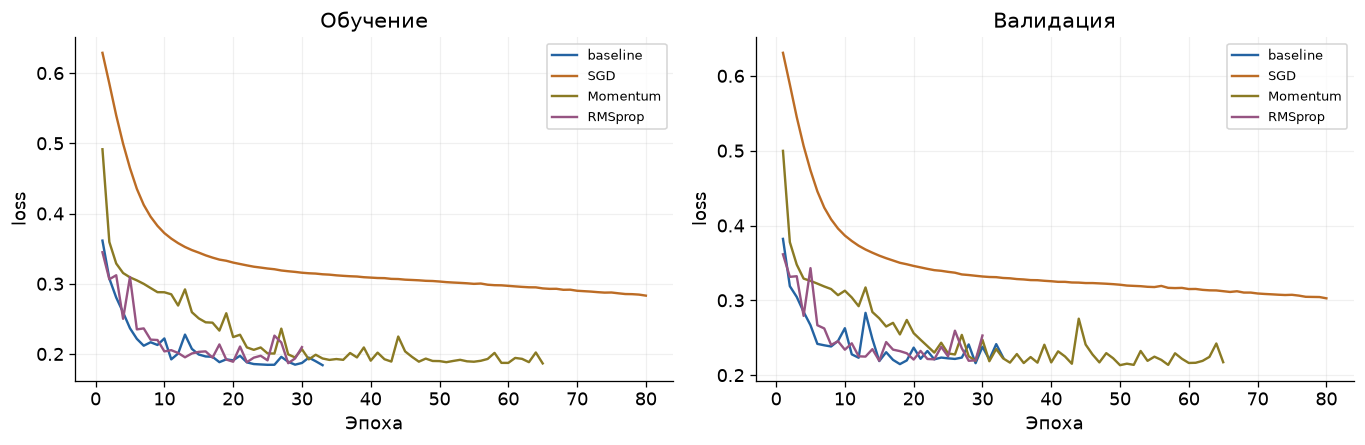

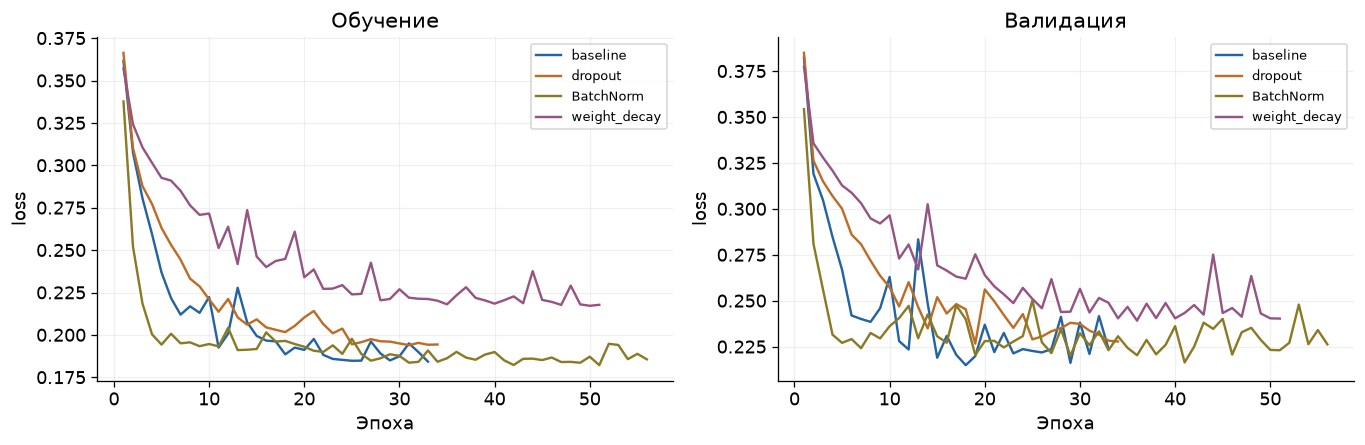

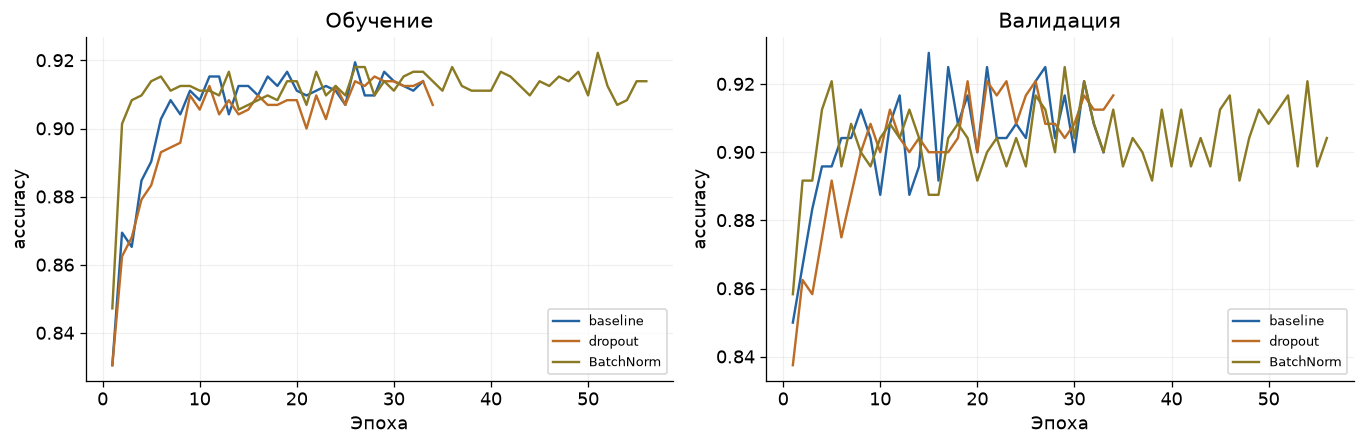

Аугментация (малый шум признаков): {'accuracy': 0.9208333333333333, 'macro_f1': 0.9208209616085847}


Dropout и BatchNorm меняют модель, weight decay — целевое правило регуляризации, early stopping — момент остановки, аугментация — распределение обучающих входов. Сравнения выполнялись по одному фактору относительно baseline.

In [2]:
from sklearn.datasets import make_moons
from scipy.stats import t as student_t

X, y = make_moons(1200, noise=0.28, random_state=11)
train, val, test = split3(X, y)
seed_all()
small = (train[0][:32], train[1][:32])
check = MLP(2, 2, (64, 64))
check, h, t = fit(check, small, small, epochs=200, lr=0.01)
print("32 объекта:", classify(check, small)[0])
rows = []
curves = {}
models = {}
configs = [
    ("baseline", "Adam", 0.01, 0.0, False, 0.0, 64),
    ("SGD", "SGD", 0.03, 0.0, False, 0.0, 64),
    ("Momentum", "Momentum", 0.03, 0.0, False, 0.0, 64),
    ("RMSprop", "RMSprop", 0.003, 0.0, False, 0.0, 64),
    ("dropout", "Adam", 0.01, 0.3, False, 0.0, 64),
    ("BatchNorm", "Adam", 0.01, 0.0, True, 0.0, 64),
    ("weight_decay", "Adam", 0.01, 0.0, False, 0.01, 64),
    ("batch16", "Adam", 0.01, 0.0, False, 0.0, 16),
    ("lr_small", "Adam", 0.001, 0.0, False, 0.0, 64),
    ("lr_large", "Adam", 0.1, 0.0, False, 0.0, 64),
]
for name, opt, lr, drop, bn, wd, bs in configs:
    seed_all()
    m = MLP(2, 2, (32, 32), dropout=drop, bn=bn)
    m, h, t = fit(
        m,
        train,
        val,
        epochs=80,
        lr=lr,
        optimizer=opt,
        weight_decay=wd,
        batch=bs,
        patience=15,
    )
    metrics, _, _ = classify(m, val)
    rows.append(
        {
            "name": name,
            "optimizer": opt,
            "lr": lr,
            "dropout": drop,
            "bn": bn,
            "weight_decay": wd,
            "batch": bs,
            "seed": 11,
            **metrics,
            "seconds": t,
        }
    )
    curves[name] = h
    models[name] = m
df = table(rows, OUT)
histories({k: curves[k] for k in ["baseline", "SGD", "Momentum", "RMSprop"]}, OUT)
histories(
    {k: curves[k] for k in ["baseline", "dropout", "BatchNorm", "weight_decay"]},
    OUT,
    "regularization",
)
histories(
    {k: curves[k] for k in ["baseline", "dropout", "BatchNorm"]},
    OUT,
    "accuracy",
    metric="accuracy",
)
seed_all()
aug = MLP(2, 2, (32, 32))
aug, h, t = fit(
    aug,
    train,
    val,
    epochs=80,
    lr=0.01,
    augment=lambda x: x + 0.04 * torch.randn_like(x),
)
print("Аугментация (малый шум признаков):", classify(aug, val)[0])
note(
    "Dropout и BatchNorm меняют модель, weight decay — целевое правило регуляризации, early stopping — момент остановки, аугментация — распределение обучающих входов. Сравнения выполнялись по одному фактору относительно baseline."
)

## Вариант 11. Пять seed и доверительный интервал

Меняю инициализацию и порядок batch. Архитектура, данные, оптимизатор и число эпох одинаковые. Считаю среднее, стандартное отклонение и 95% t-интервал по пяти seed. Этот интервал учитывает разброс запусков на одной выборке.

,seed,accuracy,macro_f1,seconds
0,11,0.90833,0.90828,0.28241
1,12,0.92917,0.92917,0.27931
2,13,0.92917,0.92917,0.27443
3,14,0.91250,0.91246,0.27454
4,15,0.92500,0.92500,0.27580


,metric,n,mean,sample_std,CI95_low,CI95_high
0,validation macro-F1,5,0.92081,0.0098,0.90865,0.93298


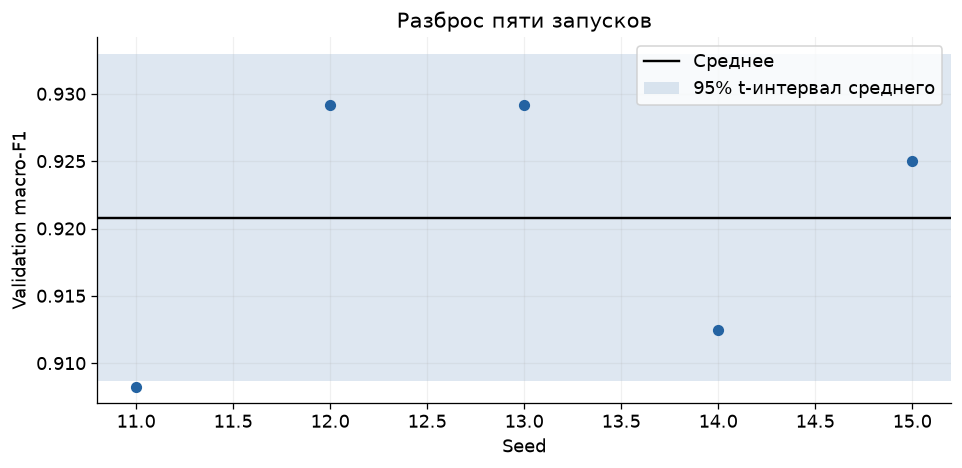

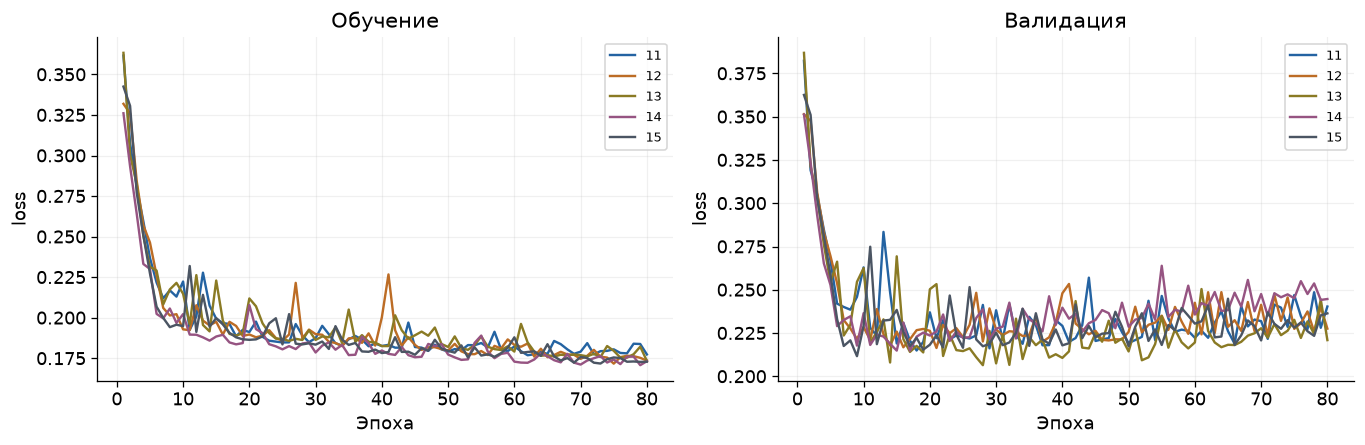

Лучшая конфигурация по validation: batch16 финальный test: {'accuracy': 0.9333333333333333, 'macro_f1': 0.9333148096693527}


,index,true,predicted,confidence,probability_margin,analysis
0,15,1,0,0.85527,0.71053,Уверенная ошибка: проверить неоднозначность пр...
1,27,0,1,0.61522,0.23044,Ошибка при близких вероятностях классов
2,53,0,1,0.83626,0.67253,Уверенная ошибка: проверить неоднозначность пр...
3,57,1,0,0.75135,0.50270,Уверенная ошибка: проверить неоднозначность пр...
4,91,0,1,0.57583,0.15165,Ошибка при близких вероятностях классов
5,92,0,1,0.59743,0.19485,Ошибка при близких вероятностях классов
6,96,0,1,0.53589,0.07177,Ошибка при близких вероятностях классов
7,103,1,0,0.90709,0.81418,Уверенная ошибка: проверить неоднозначность пр...
8,128,0,1,0.56078,0.12157,Ошибка при близких вероятностях классов
9,136,1,0,0.98718,0.97436,Уверенная ошибка: проверить неоднозначность пр...


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

Средний macro-F1=0.9208, выборочное стандартное отклонение=0.0098, 95% t-интервал [0.9086; 0.9330]. При n=5 оценка интервала нестабильна; расширение числа seed и повторение split улучшат оценку воспроизводимости.

In [3]:
rows = []
seedcurves = {}
for seed in [11, 12, 13, 14, 15]:
    seed_all(seed)
    m = MLP(2, 2, (32, 32))
    m, h, t = fit(m, train, val, epochs=80, lr=0.01, seed=seed)
    metrics, _, _ = classify(m, val)
    rows.append({"seed": seed, **metrics, "seconds": t})
    seedcurves[str(seed)] = h
sd = table(rows, OUT, "five_seeds")
values = sd.macro_f1.to_numpy()
mean = values.mean()
std = values.std(ddof=1)
half = student_t.ppf(0.975, 4) * std / np.sqrt(5)
table(
    [
        {
            "metric": "validation macro-F1",
            "n": 5,
            "mean": mean,
            "sample_std": std,
            "CI95_low": mean - half,
            "CI95_high": mean + half,
        }
    ],
    OUT,
    "confidence_interval",
)
plt.plot(sd.seed, sd.macro_f1, "o")
plt.axhline(mean, color="black", label="Среднее")
plt.axhspan(mean - half, mean + half, alpha=0.15, label="95% t-интервал среднего")
plt.xlabel("Seed")
plt.ylabel("Validation macro-F1")
plt.title("Разброс пяти запусков")
plt.legend()
showfig("seed_interval", OUT)
histories(seedcurves, OUT, "seed_curves")
best = df.sort_values("macro_f1", ascending=False).iloc[0]["name"]
model = models[best]
print(
    "Лучшая конфигурация по validation:",
    best,
    "финальный test:",
    classify(model, test)[0],
)
errors(model, test, OUT)
note(
    f"Средний macro-F1={mean:.4f}, выборочное стандартное отклонение={std:.4f}, 95% t-интервал [{mean-half:.4f}; {mean+half:.4f}]. При n=5 оценка интервала нестабильна; расширение числа seed и повторение split улучшат оценку воспроизводимости."
)

## Ответы на контрольные вопросы

1. При переобучении train loss уменьшается при росте validation loss. Плохой learning rate может мешать снижению обеих ошибок или вызывать колебания.

2. Adam и SGD используют разные геометрии и траектории обновлений; быстрая оптимизация train не гарантирует меньшего риска на новых данных.

3. Регуляризация ограничивает допустимое решение или процесс обучения; новые данные расширяют наблюдаемое распределение. Аугментация добавляет выбранные преобразования существующих примеров.

4. Один seed не показывает разброс из-за инициализации и порядка minibatch; здесь выполнены пять парных запусков.

5. В eval dropout отключает случайное зануление; используется детерминированный проход всей сети.